# How "complex" is jazz harmony? Chord complexity in 1,186 jazz standards (RQ1)

**Author:** Calvin Pan
**Date created:** October 10, 2026
**Date last modified:** October 10, 2026

This is a fun side project I started alongside my Impact Evaluations class (LPPA 7220) in UVA Batten's Master of Public Policy program.

Jazz is known for "complex" chords: 7ths, diminished 7ths, 9ths, 11ths, 13ths, and altered chords (b9, #9, #11, b13, etc.). This notebook answers my first research question:

**RQ1 (descriptive):** How often do complex chords show up in jazz standards, how does that vary *within* jazz (major vs. minor key tunes, 4/4 vs. waltzes), and how has it changed *over time*?

My second question, whether tunes with more complex harmony get recorded or listened to more, is in the companion notebook `jazzchords_pan_rq2_popularity.ipynb` (still a work in progress).

There is no single accepted definition of "chord complexity," so I compute **five** different measures and report them side by side as a robustness check:

1. **Vocabulary tier (1–5):** a nested hierarchy inspired by the [MIREX](https://www.music-ir.org/mirex/wiki/2021:Audio_Chord_Estimation) chord-estimation vocabularies (maj/min triads ⊂ other triads ⊂ sevenths ⊂ other tetrads ⊂ extended/altered chords).
2. **Pitch-class count:** the number of distinct notes in the chord (including a slash bass note).
3. **Dissonance:** how dissonant the notes in the chord sound together, using Huron's (1994) interval-class consonance ratings (one of the models in Harrison & Pearce's 2020 `incon` package).
4. **Surprisal:** how unexpected a chord is given the chord before it, in bits, from a chord-transition model trained on the rest of the corpus. This is a simplified version of the approach in [Cheung et al. (2019)](https://doi.org/10.1016/j.cub.2019.09.067).
5. **Tonal complexity:** how spread out a tune's notes are around the circle of fifths, following Weiß & Müller (2014). 0 = everything in one key area, 1 = all 12 notes used evenly.

**Data source:** [iRb Corpus of Jazz Standards](https://zenodo.org/records/3546040) (CC BY 4.0): 1,186 lead sheets converted from iReal Pro's "Jazz 1200" playlist, as used in [Broze & Shanahan (2013)](https://doi.org/10.1525/mp.2013.31.1.32). Descriptive stats from the original conversion are [here](http://icmpc-escom2012.web.auth.gr/files/papers/909_Proc.pdf).

### NOTE: The iRb corpus downloads automatically in Section 1. Run this notebook before the RQ2 notebook.

Section 7 saves the tune-level complexity measures to `output/`, and the RQ2 notebook loads them from there.

Folder structure:

challenge2_jazzchords/
                    -- jazzchords_pan_rq1_complexity.ipynb (this notebook)
                    -- jazzchords_pan_rq2_popularity.ipynb
                    -- rawdata (created automatically: iRb corpus)
                    -- output (created automatically: tables, figures, and the files RQ2 loads)  

### 0. Install packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import re
import os
import io
import glob
import time
import html
import zipfile
import unicodedata
import urllib.parse
import requests
from itertools import combinations

### 1. Load the iRb corpus
This downloads the corpus from Zenodo (only the first time), then reads in all 1,186 `.jazz` files. Each file is one lead sheet in a [Humdrum](https://www.humdrum.org/)-like text format.

In [2]:
# Set directories
dir = "/Users/calvin/Library/Mobile Documents/com~apple~CloudDocs/Documents/Calvin/UVA/2026-27/LPPA_7220_Impact_Evals/python/impactevals/challenge2_jazzchords/"
rawdata_dir = dir + "rawdata/"
output_dir = dir + "output/"
irb_dir = rawdata_dir + "iRb_v1-0/"

os.makedirs(rawdata_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

In [3]:
# Download the iRb corpus from Zenodo if it's not already in rawdata/ (only runs once)
# The Zenodo zip has another zip inside it (iRb_v1-0.zip) that holds the actual .jazz files
if not os.path.exists(irb_dir):
    zenodo_url = "https://zenodo.org/api/records/3546040/files/shanahdt/irealb-v1.0.zip/content"
    response = requests.get(zenodo_url, timeout=60)
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as outer:
        inner_name = [n for n in outer.namelist() if n.endswith("iRb_v1-0.zip")][0]
        with zipfile.ZipFile(io.BytesIO(outer.read(inner_name))) as inner:
            keep = [n for n in inner.namelist() if n.startswith("iRb_v1-0/")] # Skip the __MACOSX junk folder
            inner.extractall(rawdata_dir, members=keep)

files = sorted(glob.glob(irb_dir + "*.jazz"))
len(files) # Should be 1186

1186

Here's what one file looks like. Each chord line is a **duration** (1 = whole note, 2 = half note, 2. = dotted half) followed by a **chord symbol**. In the chord symbols, `-` means flat (so `B-:maj7` = B♭maj7), `h7` = half-diminished, `o7` = diminished 7th, and `/X` is a slash bass note. Section labels start with `*>`, and the `*>[A,A,B,C]` line gives the order the sections are played in.

In [4]:
# Print the first 30 lines of Autumn Leaves
with open(irb_dir + "autumnleaves.jazz") as f:
    print("".join(f.readlines()[:30]))

!!!OTL: Autumn Leaves
!!!COM: Kosma, Joseph
!!!ODT: 1947
**jazz
*>[A,A,B,C]
*>A
*M4/4
*g:
1C:min7
=
1F7
=
1B-:maj7
=
1E-:maj7
=
1Ah7
=
1D7b13
=
1G:min6
=
1G:min6
==
*>B
1Ah7
=
1D7b13
=
1G:min6



In [5]:
# Read one .jazz file → metadata, key, meter, and the list of chord tokens in played order
def read_irb_file(path):
    with open(path, encoding="utf-8", errors="replace") as f:
        lines = [line.strip() for line in f]

    # Metadata lines look like "!!!OTL: Autumn Leaves" (OTL = title, COM = composer, ODT = date)
    meta = {}
    for line in lines:
        m = re.match(r"^!!!(\w+):\s*(.*)$", line)
        if m and m.group(1) not in meta:
            meta[m.group(1)] = m.group(2)

    key = next((line[1:-1] for line in lines if re.match(r"^\*[A-Ga-g][#-]*:$", line)), None) # Lowercase key = minor
    meter = next((line[2:] for line in lines if line.startswith("*M")), None)
    form = next((line[3:-1].split(",") for line in lines if line.startswith("*>[")), None) # e.g. ["A", "A", "B", "C"]

    # Collect the chord tokens under each section label
    sections = {"_start": []}
    section_order = []
    current = "_start"
    for line in lines:
        if line.startswith("*>") and not line.startswith("*>["):
            current = line[2:]
            sections.setdefault(current, [])
            section_order.append(current)
        elif line and not line.startswith(("!", "*", "=")):   # Skip comments, interpretations, and barlines
            sections[current].append(line)

    # Expand the form, so a repeated A section counts every time it's played.
    # 133 files have no form line; for those, just read the sections top to bottom.
    if form is None:
        form = section_order
    tokens = sections["_start"] + [t for s in form for t in sections.get(s, [])]
    return meta, key, meter, tokens

In [6]:
# Loop through all files
tune_rows = []
token_rows = []
for path in files:
    meta, key, meter, tokens = read_irb_file(path)
    tune_id = os.path.basename(path).replace(".jazz", "")
    tune_rows.append({"tune_id": tune_id,
                      "title": meta.get("OTL"),
                      "composer": meta.get("COM"),
                      "year": int(meta["ODT"]),
                      "key": key,
                      "meter": meter})
    for token in tokens:
        token_rows.append({"tune_id": tune_id, "token": token})

tunes = pd.DataFrame(tune_rows)
tokens = pd.DataFrame(token_rows)

# Checks
display(tunes.head())
print(str(len(tunes)) + " tunes, " + str(len(tokens)) + " chord tokens")

,tune_id,title,composer,year,key,meter
0,26-2,26-2,"Coltrane, John",1959,F,4/4
1,500mileshigh,500 Miles High,"Corea, Chick",1972,e,4/4
2,502blues,502 Blues,"Rowles, Jimmy",1966,a,3/4
3,52ndstreettheme,52nd Street Theme,"Monk, Thelonious",1948,C,4/4
4,920special,9.20 Special,"Warren, Earl",1945,C,4/4


1186 tunes, 60353 chord tokens


### 2. Parse chord symbols into pitch-class sets
To measure complexity, I need to know which notes are in each chord. I turn each chord symbol into a **pitch-class set**, i.e. the set of notes in the chord as numbers 0–11 (C = 0, C♯/D♭ = 1, ..., B = 11).

How the parser reads a chord symbol, using `D7b9/F#` as the example:
1. Root: `D` → 2.
2. Base quality: the longest spelling in `BASE_QUALITIES` that the symbol starts with. Here that's `7` (dominant 7th = root, major 3rd, 5th, ♭7 → semitones 0, 4, 7, 10).
3. Modifiers: anything left over (`b9` → add semitone 1, `sus` → swap the 3rd for a 4th, `#5` → raise the 5th, `alt` → ♭9 + ♯9 + ♭13 with no 5th).
4. Slash bass: `/F#` → add F♯ (6) if it isn't already in the chord.

iRb charts sometimes include an alternate chord in parentheses, e.g. `C7(G:min7)`. I drop those and keep the main chord. `r` = rest / no chord, which I skip.

Defaults I chose: a "13" chord is root-3-5-♭7-9-13 (the 11 is usually left out on dominant chords), and an "11" chord is root-5-♭7-9-11 (the 3rd is usually left out).

In [7]:
NOTE_PCS = {"C": 0, "D": 2, "E": 4, "F": 5, "G": 7, "A": 9, "B": 11}

def note_to_pc(note):
    # "B-" → 10, "F#" → 6
    return (NOTE_PCS[note[0]] + note.count("#") - note.count("-")) % 12

# Base chord qualities, as semitones above the root. Order matters: longer spellings come first so "min7" is checked before "min".
BASE_QUALITIES = [
    ("min:maj7", [0, 3, 7, 11]),
    ("min69",    [0, 3, 7, 9, 2]),
    ("min11",    [0, 3, 7, 10, 2, 5]),
    ("min9",     [0, 3, 7, 10, 2]),
    ("min7b5",   [0, 3, 6, 10]),       # Same thing as half-diminished
    ("min7",     [0, 3, 7, 10]),
    ("minb6",    [0, 3, 7, 8]),
    ("min6",     [0, 3, 7, 9]),
    ("min",      [0, 3, 7]),
    ("maj9",     [0, 4, 7, 11, 2]),
    ("maj7",     [0, 4, 7, 11]),
    ("maj",      [0, 4, 7]),
    ("^9",       [0, 4, 7, 11, 2]),    # ^ is iReal shorthand for maj7
    ("^",        [0, 4, 7, 11]),
    ("h7",       [0, 3, 6, 10]),       # Half-diminished (ø7)
    ("h",        [0, 3, 6, 10]),
    ("dim7",     [0, 3, 6, 9]),
    ("o7",       [0, 3, 6, 9]),        # Diminished 7th (°7)
    ("o",        [0, 3, 6]),           # Diminished triad
    ("+",        [0, 4, 8]),           # Augmented triad
    ("69",       [0, 4, 7, 9, 2]),
    ("6",        [0, 4, 7, 9]),
    ("13",       [0, 4, 7, 10, 2, 9]),
    ("11",       [0, 7, 10, 2, 5]),
    ("9",        [0, 4, 7, 10, 2]),
    ("7",        [0, 4, 7, 10]),       # Dominant 7th
    ("add9",     [0, 4, 7, 2]),
    ("sus",      [0, 5, 7]),
    ("",         [0, 4, 7]),           # Plain major triad
]

# Modifiers that add a note (semitones above root)
ADDED_TONES = {"b9": 1, "9": 2, "#9": 3, "11": 5, "#11": 6, "b13": 8, "13": 9, "6": 9, "b6": 8, "add9": 2, "add3": 4}
ALTERATIONS = {"b9", "#9", "#11", "b13", "#5", "+", "b5", "alt"}

In [8]:
def parse_chord(token):
    # Split "2.C7b9/G" into duration ("2.") and symbol ("C7b9/G")
    m = re.match(r"^(\d+)(\.*)(.*)$", token)
    if not m:
        return None
    duration = (1 / int(m.group(1))) * (1.5 ** len(m.group(2)))   # In whole notes; each dot = x1.5
    symbol = re.sub(r"\(.*?\)", "", m.group(3))                     # Drop alternate chords in parentheses
    symbol = symbol.replace(";", "").replace("*", "")               # Drop stray characters
    if symbol in ("r", ""):
        return None                                                 # Rest / no chord

    # Root
    m = re.match(r"^([A-G][#-]*)(.*)$", symbol)
    if not m:
        return None
    root = note_to_pc(m.group(1))

    # Quality and slash bass
    quality, _, bass = m.group(2).partition("/")
    quality = re.sub(r"(?<!s)u", "sus", quality.lstrip(":"))        # A few charts write "7u" for 7sus

    for spelling, intervals in BASE_QUALITIES:
        if quality.startswith(spelling):
            base = spelling
            rest = quality[len(spelling):]
            tones = set(intervals)
            break

    # Modifiers
    mods = re.findall(r"sus|add\d+|alt|[b#]\d+|\+|69|\d+", rest)
    if "".join(mods) != rest:
        return None                                                 # Couldn't read part of the symbol
    for mod in mods:
        if mod == "sus":
            tones = (tones - {3, 4}) | {5}
        elif mod == "alt":
            tones = (tones - {7}) | {1, 3, 8}
        elif mod == "b5":
            tones = (tones - {7}) | {6}
        elif mod in ("#5", "+"):
            tones = (tones - {7}) | {8}
        elif mod == "69":
            tones = tones | {9, 2}
        elif mod in ADDED_TONES:
            tones = tones | {ADDED_TONES[mod]}
        else:
            return None

    pcs = {(root + t) % 12 for t in tones}
    bass_pc = None
    if bass:
        if not re.match(r"^[A-G][#-]*$", bass):
            return None
        bass_pc = note_to_pc(bass)
        pcs.add(bass_pc)

    return {"duration": duration, "root": root, "quality": quality, "base": base,
            "mods": mods, "bass": bass_pc, "pcs": frozenset(pcs)}

# Test on a few examples
for t in ["1C:min7", "2D7b9/F#", "1B-:maj7", "2Ah7", "1G7alt", "2E-7sus", "1r"]:
    print(t, "→", parse_chord(t))

1C:min7 → {'duration': 1.0, 'root': 0, 'quality': 'min7', 'base': 'min7', 'mods': [], 'bass': None, 'pcs': frozenset({0, 10, 3, 7})}
2D7b9/F# → {'duration': 0.5, 'root': 2, 'quality': '7b9', 'base': '7', 'mods': ['b9'], 'bass': 6, 'pcs': frozenset({0, 2, 3, 6, 9})}
1B-:maj7 → {'duration': 1.0, 'root': 10, 'quality': 'maj7', 'base': 'maj7', 'mods': [], 'bass': None, 'pcs': frozenset({9, 10, 2, 5})}
2Ah7 → {'duration': 0.5, 'root': 9, 'quality': 'h7', 'base': 'h7', 'mods': [], 'bass': None, 'pcs': frozenset({0, 9, 3, 7})}
1G7alt → {'duration': 1.0, 'root': 7, 'quality': '7alt', 'base': '7', 'mods': ['alt'], 'bass': None, 'pcs': frozenset({3, 5, 7, 8, 10, 11})}
2E-7sus → {'duration': 0.5, 'root': 3, 'quality': '7sus', 'base': '7', 'mods': ['sus'], 'bass': None, 'pcs': frozenset({8, 1, 10, 3})}
1r → None


In [9]:
# Parse every token
parsed = tokens["token"].apply(parse_chord)
is_rest = tokens["token"].str.match(r"^\d+\.*r$")

# Checks: which tokens failed to parse (excluding rests)?
display(tokens.loc[parsed.isna() & ~is_rest, "token"].value_counts())

chords = pd.concat([tokens.loc[parsed.notna(), "tune_id"].reset_index(drop=True),
                    pd.DataFrame(parsed.dropna().tolist())], axis=1)
print(str(len(chords)) + " chords parsed")

token
D-9                1
2A:min(C7/B-)D7    1
Name: count, dtype: int64

60285 chords parsed


**Chord families.** For the frequency tables I sort every chord into one family. Families roughly follow how I'd think about complexity as a player: triads → 6ths and 7ths → 9ths/11ths/13ths → altered chords. Any alteration (♭9, ♯9, ♯11, ♭13, ♯5, ♭5, alt) puts a chord in "Altered," even if it's also extended.

The **vocabulary tier** (measure #1) maps these families onto a nested 1–5 scale, inspired by the MIREX chord vocabularies (`majmin` ⊂ `sevenths` ⊂ `tetrads` ⊂ `full`):

| Tier | Families |
|---|---|
| 1 | Major/minor triads |
| 2 | Diminished, augmented, and sus triads |
| 3 | Sevenths (maj7, min7, dominant 7, 7sus) |
| 4 | Other four-note chords (6, min6, ø7, °7, min-maj7) |
| 5 | Extended (9, 11, 13, add9, 6/9) or altered chords |

In [10]:
def chord_family(base, mods):
    if any(m in ALTERATIONS for m in mods):
        return "Altered"
    if base in ("min9", "min11", "maj9", "^9", "13", "11", "9", "add9", "69", "min69") or any(m in ("9", "11", "13", "add9", "69", "add3") for m in mods):
        return "Extended"
    if base in ("", "maj", "min"):
        return "Dim/aug/sus triad" if "sus" in mods else "Maj/min triad"
    if base in ("o", "+", "sus"):
        return "Dim/aug/sus triad"
    if base in ("6", "min6", "minb6") or "6" in mods or "b6" in mods:
        return "Sixth"
    if base in ("h7", "h", "min7b5"):
        return "Half-dim 7th"
    if base in ("o7", "dim7"):
        return "Dim 7th"
    if base == "min:maj7":
        return "Min-maj 7th"
    return "Seventh"   # maj7, min7, 7, 7sus

TIER = {"Maj/min triad": 1, "Dim/aug/sus triad": 2, "Seventh": 3,
        "Sixth": 4, "Half-dim 7th": 4, "Dim 7th": 4, "Min-maj 7th": 4,
        "Extended": 5, "Altered": 5}

chords["family"] = [chord_family(b, m) for b, m in zip(chords["base"], chords["mods"])]

# Checks: most common qualities in each family
chords.groupby("family")["quality"].agg(lambda s: ", ".join(s.value_counts().head(6).index))

family
Altered              7b9, 7#11, 7#5, 7#9, maj7#11, 7b13
Dim 7th                                        o7, dim7
Dim/aug/sus triad                             o, +, sus
Extended                   9, 13, min11, min9, 9sus, 69
Half-dim 7th                              h7, h, min7b5
Maj/min triad                                , min, maj
Min-maj 7th                                    min:maj7
Seventh                          7, min7, maj7, 7sus, ^
Sixth                                    6, min6, minb6
Name: quality, dtype: object

### 3. Collapse repeated chords into chord *changes*
iRb writes a chord again in every bar it lasts (a Gm6 held for two bars shows up twice). If I counted those as two chords, long-held chords would get extra weight. So I merge back-to-back identical chords (same root, quality, and bass) into one **chord change** and add up their durations.

In [11]:
# A new chord change starts whenever the chord differs from the one right before it (within the same tune)
chords["chord_id"] = chords["root"].astype(str) + "|" + chords["quality"] + "|" + chords["bass"].astype(str)
new_change = chords["chord_id"] != chords.groupby("tune_id")["chord_id"].shift()
chords["change_n"] = new_change.groupby(chords["tune_id"]).cumsum()

changes = (chords.groupby(["tune_id", "change_n"], sort=False)
                 .agg(duration=("duration", "sum"), root=("root", "first"), quality=("quality", "first"),
                      bass=("bass", "first"), pcs=("pcs", "first"), family=("family", "first"))
                 .reset_index())

print(str(len(chords)) + " chords → " + str(len(changes)) + " chord changes")

60285 chords → 54386 chord changes


### 4. Compute the five complexity measures
#### 4.1 Vocabulary tier and 4.2 pitch-class count

In [12]:
changes["tier"] = changes["family"].map(TIER)
changes["n_pcs"] = changes["pcs"].apply(len)   # Number of distinct notes, including a slash bass

#### 4.3 Dissonance
[Huron (1994)](https://doi.org/10.2307/40285624) rated how consonant each interval class sounds (e.g. a perfect 5th/4th is very consonant, a minor 2nd/major 7th is very dissonant). A chord's consonance is built from all the pairs of notes in it.

Huron's original measure *adds up* the pairs. But then a chord with more notes gets more consonant pairs, and in practice a C9 scored as *more* consonant than a C triad. So I take the **average** over pairs instead and flip the sign, so higher = more dissonant. Averaging also keeps this measure from just tracking pitch-class count.

In [13]:
# Huron (1994) consonance values for interval classes 1–6 (ic1 = minor 2nd/major 7th, ..., ic6 = tritone)
HURON = {1: -1.428, 2: -0.582, 3: 0.594, 4: 0.386, 5: 1.240, 6: -0.453}

def dissonance(pcs):
    pair_values = []
    for a, b in combinations(sorted(pcs), 2):     # Every pair of notes in the chord
        ic = min((a - b) % 12, (b - a) % 12)      # Interval class: 1–6
        pair_values.append(HURON[ic])
    return -np.mean(pair_values)                  # Negative so that higher = more dissonant

changes["dissonance"] = changes["pcs"].apply(dissonance)

# Checks: a triad should be less dissonant than a dom7, which should be less dissonant than a 7b9
print(dissonance({0, 4, 7}), dissonance({0, 4, 7, 10}), dissonance({0, 4, 7, 10, 1}))

-0.7399999999999999 -0.2965 -0.1086


#### 4.4 Surprisal
Surprisal measures how unexpected a chord is *in context*: −log₂ P(chord | previous chord), in bits. Following Cheung et al. (2019), I estimate the probabilities from a chord-transition (bigram) model:

- **Transposition-invariant:** the "outcome" is the interval the root moves by plus the new chord's quality (e.g. `5|7` = "up a 4th to a dominant 7th"), and the "context" is the previous chord's quality. So ii–V in C and ii–V in E♭ count as the same move.
- **Leave-one-tune-out:** each tune's own transitions are subtracted from the counts before scoring it. Otherwise a tune with a weird progression would partly "explain itself."
- **Add-k smoothing (k = 0.1):** keeps unseen transitions from getting probability 0 (infinite surprisal).

Cheung et al. use a more sophisticated multi-order model (IDyOM-style), so this is a simplified version.

In [14]:
K = 0.1   # Smoothing constant

changes["context"] = changes.groupby("tune_id")["quality"].shift()                     # Previous chord's quality
root_move = (changes["root"] - changes.groupby("tune_id")["root"].shift()) % 12         # Root movement in semitones
changes["outcome"] = root_move.astype("Int64").astype(str) + "|" + changes["quality"]

transitions = changes.dropna(subset=["context"])   # First chord of each tune has no context
V = transitions["outcome"].nunique()               # Number of possible outcomes (for smoothing)

# Counts across the whole corpus...
pair_all = transitions.groupby(["context", "outcome"]).size()
ctx_all = transitions.groupby("context").size()
# ...and within each tune (to subtract out)
pair_own = transitions.groupby(["tune_id", "context", "outcome"]).size()
ctx_own = transitions.groupby(["tune_id", "context"]).size()

# Look up the right count for every row
pair_all_n = pair_all.reindex(pd.MultiIndex.from_frame(transitions[["context", "outcome"]])).to_numpy()
ctx_all_n = ctx_all.reindex(transitions["context"]).to_numpy()
pair_own_n = pair_own.reindex(pd.MultiIndex.from_frame(transitions[["tune_id", "context", "outcome"]])).to_numpy()
ctx_own_n = ctx_own.reindex(pd.MultiIndex.from_frame(transitions[["tune_id", "context"]])).to_numpy()

# Leave-one-tune-out probability with add-k smoothing
prob = (pair_all_n - pair_own_n + K) / (ctx_all_n - ctx_own_n + K * V)
changes.loc[transitions.index, "surprisal"] = -np.log2(prob)

# Checks: most and least surprising common transitions
check = changes.groupby(["context", "outcome"])["surprisal"].agg(["mean", "size"])
display(check[check["size"] >= 50].sort_values("mean").head(5))
display(check[check["size"] >= 50].sort_values("mean").tail(5))

,,mean,size
context,outcome,,
h,5|7,0.839130,101
min7,5|7,0.937497,7448
h7,5|7b9,0.984702,1134
7b13,5|min7,1.205914,165
7b9,5|min7,1.229478,1014


mean  size
context outcome                
7       5|7sus   8.207384    56
        8|min7   8.236082    54
        1|maj7   8.237560    53
        0|7      8.341233    50
        5|7b9    8.549448    52

#### 4.5 Tonal complexity
Weiß & Müller (2014): put a tune's notes on the circle of fifths (C, G, D, A, ...), weighted by how long each note sounds, and compute the length of the average vector, r. If all the notes are bunched in one region of the circle (one key), r ≈ 1. If they're spread evenly around it, r ≈ 0. Tonal complexity = √(1 − r).

This one is a **tune-level** measure: it describes the whole tune's harmony, not single chords. I also compute it for individual chords so the chord-level table in Section 6 (Table 1) has all five columns.

In [15]:
def tonal_complexity(chroma):
    # chroma = length-12 array of how much each pitch class (C, C#, ..., B) is used
    chroma = np.asarray(chroma, dtype=float)
    angles = 2 * np.pi * 7 * np.arange(12) / 12             # Multiplying by 7 reorders pitch classes along the circle of fifths
    r = np.abs(np.sum(chroma * np.exp(1j * angles))) / chroma.sum()
    return np.sqrt(1 - r)

def tune_chroma(df):
    # Add up each chord's duration onto the notes it contains
    chroma = np.zeros(12)
    for pcs, d in zip(df["pcs"], df["duration"]):
        chroma[list(pcs)] += d
    return chroma

# Chord-level version (each chord on its own)
changes["tonal_complexity"] = changes["pcs"].apply(lambda pcs: tonal_complexity(np.isin(np.arange(12), list(pcs))))

# Tune-level version (duration-weighted across the whole tune)
tune_tc = changes.groupby("tune_id")[["pcs", "duration"]].apply(lambda d: tonal_complexity(tune_chroma(d)))
tune_tc.describe()

count    1186.000000
mean        0.788761
std         0.064553
min         0.450876
25%         0.745459
50%         0.779450
75%         0.828088
max         1.000000
dtype: float64

### 5. Aggregate to the tune level
Each tune gets the **average** tier, pitch-class count, dissonance, and surprisal across its chord changes, plus its tune-level tonal complexity. I also add the grouping variables for the "within genre" and "over time" comparisons: era, key mode (major vs. minor), and meter.

In [16]:
measures = ["tier", "n_pcs", "dissonance", "surprisal", "tonal_complexity"]
measure_labels = {"tier": "Vocabulary tier (1–5)",
                  "n_pcs": "Pitch classes",
                  "dissonance": "Dissonance",
                  "surprisal": "Surprisal (bits)",
                  "tonal_complexity": "Tonal complexity"}

tune_level = changes.groupby("tune_id")[["tier", "n_pcs", "dissonance", "surprisal"]].mean()
tune_level["tonal_complexity"] = tune_tc
tune_level["n_changes"] = changes.groupby("tune_id").size()
tune_level = tunes.merge(tune_level, left_on="tune_id", right_index=True)

# Grouping variables
tune_level["era"] = pd.cut(tune_level["year"], bins=[0, 1929, 1939, 1949, 1959, 1969, 2100],
                           labels=["Pre-1930", "1930s", "1940s", "1950s", "1960s", "1970+"])
tune_level["minor_key"] = tune_level["key"].str[0].str.islower().astype(int)     # Lowercase key in iRb = minor
tune_level["key_mode"] = np.where(tune_level["minor_key"] == 1, "Minor key", "Major key")
tune_level["meter_group"] = np.where(tune_level["meter"].isin(["4/4", "3/4"]), tune_level["meter"], "Other")

# Standardized (z-score) versions of each measure, so they can be compared on the same scale
for m in measures:
    tune_level["z_" + m] = (tune_level[m] - tune_level[m].mean()) / tune_level[m].std()

display(tune_level[measures].describe())
tune_level["era"].value_counts(sort=False)

,tier,n_pcs,dissonance,surprisal,tonal_complexity
count,1186.000000,1186.000000,1186.000000,1186.000000,1186.000000
mean,3.304456,4.105655,-0.391365,5.007473,0.788761
std,0.426794,0.252222,0.062532,1.628993,0.064553
min,1.000000,3.000000,-0.740000,2.449511,0.450876
25%,3.094564,4.000000,-0.425860,3.788617,0.745459
50%,3.260000,4.055556,-0.396444,4.627844,0.779450
75%,3.492308,4.166667,-0.359383,5.837642,0.828088
max,5.000000,6.000000,-0.107058,11.549264,1.000000


era
Pre-1930    112
1930s       248
1940s       257
1950s       235
1960s       222
1970+       112
Name: count, dtype: int64

### 6. RQ1 results: how common are complex chords in jazz, and how has that changed?
#### Table 1: Chord families across all 1,186 tunes
The share column answers the basic frequency question. The five measure columns are chord-level means, which double as a sanity check: if the measures make sense, they should mostly agree on which families are more complex.

In [17]:
family_order = ["Maj/min triad", "Dim/aug/sus triad", "Seventh", "Sixth", "Half-dim 7th",
                "Dim 7th", "Min-maj 7th", "Extended", "Altered"]

table1 = changes.groupby("family")[measures].mean().reindex(family_order)
table1.insert(0, "Share of chord changes", changes["family"].value_counts(normalize=True).reindex(family_order))
table1.insert(0, "N chord changes", changes["family"].value_counts().reindex(family_order))
table1.insert(2, "Share of tunes using it", changes.groupby("family")["tune_id"].nunique().reindex(family_order) / len(tune_level))
table1 = table1.rename(columns=measure_labels)

table1.to_csv(output_dir + "table1_chord_families.csv")
table1.style.format({"N chord changes": "{:,.0f}", "Share of chord changes": "{:.1%}", "Share of tunes using it": "{:.1%}"}, precision=2)

,N chord changes,Share of chord changes,Share of tunes using it,Vocabulary tier (1–5),Pitch classes,Dissonance,Surprisal (bits),Tonal complexity
family,,,,,,,,
Maj/min triad,"2,415",4.4%,30.6%,1.00,3.12,-0.70,7.04,0.60
Dim/aug/sus triad,193,0.4%,6.3%,2.00,3.01,-0.32,10.49,0.84
Seventh,"37,635",69.2%,99.2%,3.00,4.01,-0.43,3.90,0.65
Sixth,"3,428",6.3%,59.9%,4.00,4.00,-0.52,5.70,0.60
Half-dim 7th,"2,344",4.3%,54.5%,4.00,4.01,-0.30,7.27,0.72
Dim 7th,"1,128",2.1%,32.7%,4.00,4.02,-0.24,7.09,1.00
Min-maj 7th,203,0.4%,6.9%,4.00,4.01,-0.26,8.76,0.87
Extended,"1,755",3.2%,22.0%,5.00,5.31,-0.28,9.91,0.64
Altered,"5,285",9.7%,71.8%,5.00,4.94,-0.07,7.14,0.87


In [18]:
# The headline number: share of chord changes that are beyond plain triads (tier 3+)
share_complex = (changes["tier"] >= 3).mean()
share_ext_alt = (changes["tier"] == 5).mean()
print("Share of chord changes that are 7ths or more complex (tier 3+): " + str(round(share_complex * 100, 1)) + "%")
print("Share of chord changes that are extended or altered (tier 5): " + str(round(share_ext_alt * 100, 1)) + "%")

Share of chord changes that are 7ths or more complex (tier 3+): 95.2%
Share of chord changes that are extended or altered (tier 5): 12.9%


#### Figure 1: Chord-family mix by era
I combine the 9 families into 6 groups so the stacked bars stay readable.

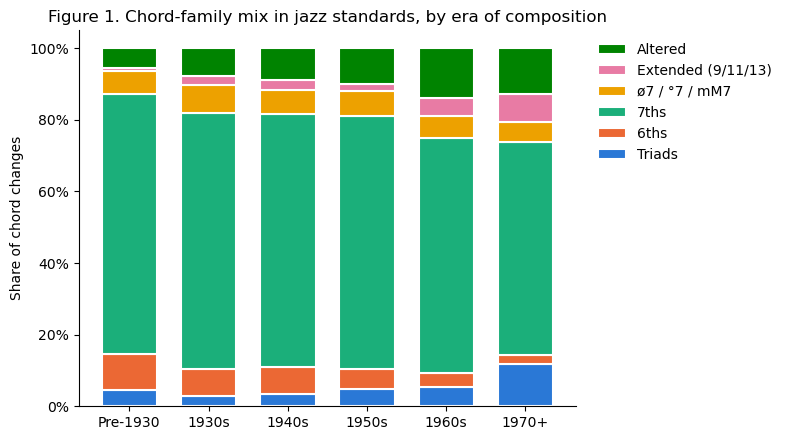

group,Triads,6ths,7ths,ø7 / °7 / mM7,Extended (9/11/13),Altered
era,,,,,,
Pre-1930,4.6%,10.0%,72.7%,6.3%,0.9%,5.5%
1930s,2.9%,7.5%,71.5%,7.7%,2.8%,7.6%
1940s,3.4%,7.6%,70.6%,6.7%,2.7%,9.0%
1950s,4.7%,5.6%,70.8%,7.0%,2.0%,9.9%
1960s,5.5%,3.8%,65.7%,6.1%,4.8%,14.0%
1970+,11.8%,2.5%,59.4%,5.6%,7.8%,12.9%


In [19]:
# Combine into 6 groups for plotting (simplest at the bottom of the stack)
plot_groups = {"Maj/min triad": "Triads", "Dim/aug/sus triad": "Triads", "Sixth": "6ths",
               "Seventh": "7ths", "Half-dim 7th": "ø7 / °7 / mM7", "Dim 7th": "ø7 / °7 / mM7",
               "Min-maj 7th": "ø7 / °7 / mM7", "Extended": "Extended (9/11/13)", "Altered": "Altered"}
group_order = ["Triads", "6ths", "7ths", "ø7 / °7 / mM7", "Extended (9/11/13)", "Altered"]
group_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]   # Colorblind-checked categorical palette, fixed order

changes_era = changes.merge(tune_level[["tune_id", "era"]], on="tune_id")
changes_era["group"] = changes_era["family"].map(plot_groups)
mix = pd.crosstab(changes_era["era"], changes_era["group"], normalize="index")[group_order]

fig, ax = plt.subplots(figsize=(8, 4.5))
bottom = np.zeros(len(mix))
for group, color in zip(group_order, group_colors):
    ax.bar(mix.index.astype(str), mix[group], bottom=bottom, color=color, edgecolor="white", linewidth=1.5, label=group, width=0.7)
    bottom += mix[group].to_numpy()

ax.set_ylabel("Share of chord changes")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_title("Figure 1. Chord-family mix in jazz standards, by era of composition")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)   # Reverse so legend order matches the stack
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(output_dir + "fig1_family_mix_by_era.png", dpi=200)
plt.show()

mix.style.format("{:.1%}")

#### Table 2: All five complexity measures, within jazz and over time (robustness table)
Cells are tune-level **mean (SD)**. Panel A is over time (era of composition), and Panels B and C are within-genre splits by key mode and meter. Panel D gives the linear trend per decade from a regression of each standardized measure on year, in **SD units** so the five measures can be compared directly (robust SEs in parentheses).

If all five measures move in the same direction, I can be more confident a pattern isn't just an artifact of how I defined "complexity."

In [20]:
def summarize(df, group_col, panel):
    stats = df.groupby(group_col, observed=True)[measures].agg(["mean", "std"])
    table = pd.DataFrame(index=stats.index)
    table["N tunes"] = df.groupby(group_col, observed=True).size().astype(str)
    for m in measures:
        table[measure_labels[m]] = stats[(m, "mean")].map("{:.2f}".format) + " (" + stats[(m, "std")].map("{:.2f}".format) + ")"
    table.index = pd.MultiIndex.from_product([[panel], table.index.astype(str)])
    return table

tune_level["all"] = "All tunes"
panel_all = summarize(tune_level, "all", "All")
panel_a = summarize(tune_level, "era", "A. Era of composition")
panel_b = summarize(tune_level, "key_mode", "B. Key mode")
panel_c = summarize(tune_level, "meter_group", "C. Meter")

# Panel D: trend per decade in SD units, with robust (HC1) standard errors
tune_level["decade"] = tune_level["year"] / 10
trend = {"N tunes": str(len(tune_level))}
for m in measures:
    fit = smf.ols("z_" + m + " ~ decade", data=tune_level).fit(cov_type="HC1")
    stars = "***" if fit.pvalues["decade"] < 0.01 else "**" if fit.pvalues["decade"] < 0.05 else "*" if fit.pvalues["decade"] < 0.1 else ""
    trend[measure_labels[m]] = f"{fit.params['decade']:.3f}{stars} ({fit.bse['decade']:.3f})"
panel_d = pd.DataFrame(trend, index=pd.MultiIndex.from_tuples([("D. Trend", "Per decade (SD units)")]))

table2 = pd.concat([panel_all, panel_a, panel_b, panel_c, panel_d])
table2.to_csv(output_dir + "table2_complexity_robustness.csv")
table2

N tunes Vocabulary tier (1–5)  \
All                   All tunes                1186           3.30 (0.43)   
A. Era of composition Pre-1930                  112           3.18 (0.36)   
                      1930s                     248           3.31 (0.33)   
                      1940s                     257           3.30 (0.33)   
                      1950s                     235           3.27 (0.39)   
                      1960s                     222           3.42 (0.54)   
                      1970+                     112           3.28 (0.61)   
B. Key mode           Major key                 988           3.27 (0.39)   
                      Minor key                 198           3.49 (0.54)   
C. Meter              3/4                        79           3.36 (0.49)   
                      4/4                      1099           3.30 (0.41)   
                      Other                       8           3.06 (1.04)   
D. Trend              Per decade (SD units)    1186       0.054** (0.021)   

                                                Pitch classes     Dissonance  \
All                   All tunes                   4.11 (0.25)   -0.39 (0.06)   
A. Era of composition Pre-1930                    4.00 (0.15)   -0.41 (0.05)   
                      1930s                       4.07 (0.16)   -0.39 (0.05)   
                      1940s                       4.09 (0.17)   -0.39 (0.05)   
                      1950s                       4.08 (0.23)   -0.38 (0.06)   
                      1960s                       4.21 (0.35)   -0.38 (0.07)   
                      1970+                       4.16 (0.36)   -0.40 (0.09)   
B. Key mode           Major key                   4.08 (0.22)   -0.39 (0.06)   
                      Minor key                   4.22 (0.37)   -0.38 (0.08)   
C. Meter              3/4                         4.16 (0.33)   -0.39 (0.08)   
                      4/4                         4.10 (0.24)   -0.39 (0.06)   
                      Other                       4.05 (0.58)   -0.46 (0.14)   
D. Trend              Per decade (SD units)  0.128*** (0.021)  0.024 (0.020)   

                                             Surprisal (bits)  \
All                   All tunes                   5.01 (1.63)   
A. Era of composition Pre-1930                    4.26 (0.98)   
                      1930s                       4.39 (1.19)   
                      1940s                       4.54 (1.26)   
                      1950s                       4.83 (1.42)   
                      1960s                       5.91 (1.78)   
                      1970+                       6.78 (1.79)   
B. Key mode           Major key                   4.82 (1.55)   
                      Minor key                   5.92 (1.71)   
C. Meter              3/4                         5.84 (1.93)   
                      4/4                         4.93 (1.58)   
                      Other                       7.61 (1.40)   
D. Trend              Per decade (SD units)  0.278*** (0.018)   

                                             Tonal complexity  
All                   All tunes                   0.79 (0.06)  
A. Era of composition Pre-1930                    0.75 (0.04)  
                      1930s                       0.78 (0.05)  
                      1940s                       0.79 (0.06)  
                      1950s                       0.80 (0.07)  
                      1960s                       0.80 (0.08)  
                      1970+                       0.81 (0.08)  
B. Key mode           Major key                   0.79 (0.06)  
                      Minor key                   0.79 (0.07)  
C. Meter              3/4                         0.80 (0.07)  
                      4/4                         0.79 (0.06)  
                      Other                       0.78 (0.11)  
D. Trend              Per decade (SD units)  0.148*** (0.018)

#### Table 3: How much do the five measures agree?
These are correlations across tunes. High correlations mean the measures capture the same thing. Low ones mean "complexity" depends on which measure you pick, which is exactly why I report all five.

In [21]:
table3 = tune_level[measures].corr().rename(index=measure_labels, columns=measure_labels)
table3.to_csv(output_dir + "table3_measure_correlations.csv")
table3.style.format("{:.2f}").background_gradient(cmap="Greys", vmin=-1, vmax=1)

,Vocabulary tier (1–5),Pitch classes,Dissonance,Surprisal (bits),Tonal complexity
Vocabulary tier (1–5),1.00,0.90,0.74,0.32,0.26
Pitch classes,0.90,1.00,0.66,0.43,0.27
Dissonance,0.74,0.66,1.00,0.24,0.41
Surprisal (bits),0.32,0.43,0.24,1.00,0.28
Tonal complexity,0.26,0.27,0.41,0.28,1.00


#### Figure 2: The five measures over time, on a common (SD) scale

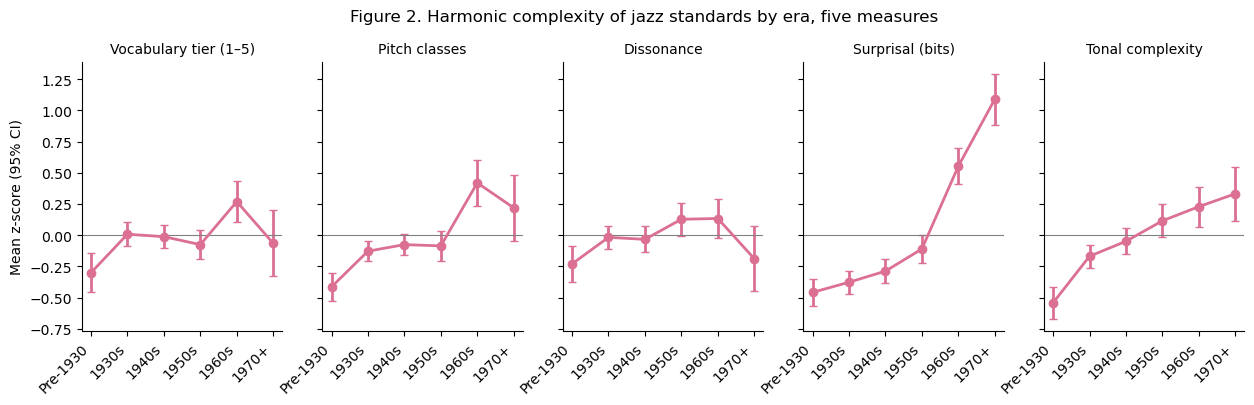

In [22]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5), sharey=True)
for ax, m in zip(axes, measures):
    era_stats = tune_level.groupby("era", observed=True)["z_" + m].agg(["mean", "sem"])
    x = np.arange(len(era_stats))
    ax.errorbar(x, era_stats["mean"], yerr=1.96 * era_stats["sem"], color="palevioletred", marker="o", markersize=6, linewidth=2, capsize=3)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(era_stats.index.astype(str), rotation=45, ha="right")
    ax.set_title(measure_labels[m], fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Mean z-score (95% CI)")
fig.suptitle("Figure 2. Harmonic complexity of jazz standards by era, five measures", y=1.03)
plt.savefig(output_dir + "fig2_measures_by_era.png", dpi=200, bbox_inches="tight")
plt.show()

### 7. Save tune-level measures for the RQ2 notebook
This saves two files that `jazzchords_pan_rq2_popularity.ipynb` loads:
1. `rq1_tune_level_complexity.csv`: the five measures (raw and standardized) plus the grouping variables, one row per tune.
2. `rq1_chord_transition_counts.csv`: the chord-transition counts behind the surprisal measure, so RQ2 can score the surprisal of new chord sequences (the Autumn Leaves recordings).

In [23]:
# Save the tune-level measures and the chord-transition counts, which the RQ2 notebook loads
save_cols = ["tune_id", "title", "composer", "year", "key", "meter", "n_changes",
             "era", "minor_key", "key_mode", "meter_group"] + measures + ["z_" + m for m in measures]
tune_level[save_cols].to_csv(output_dir + "rq1_tune_level_complexity.csv", index=False)
pair_all.rename("n").reset_index().to_csv(output_dir + "rq1_chord_transition_counts.csv", index=False)

print("Saved " + str(len(tune_level)) + " tunes and " + str(len(pair_all)) + " chord transitions")

Saved 1186 tunes and 2733 chord transitions


### Conclusion:
In jazz lead sheets, "complex" chords are the norm, not the exception. 95% of chord changes are 7ths or more complex, and plain major/minor triads are only 4.4%. Basic 7ths (maj7, min7, dom7) alone make up 69%. Altered chords (9.7%) are much more common than extended 9/11/13 chords (3.2%), mostly because lead sheets mark the b9 on V7 chords going to minor chords.

Over time, the five measures **don't all tell the same story**, which is why reporting them together is useful:
- Surprisal (+0.28 SD per decade) and tonal complexity (+0.15 SD per decade) rise steadily: later tunes move between chords in less predictable ways and use more of the circle of fifths.
- Pitch-class count rises a bit (+0.13 SD/decade), vocabulary tier barely moves (+0.05), and dissonance has no significant trend.
- So the change over time is mostly about **progressions** (where the chords go), not **chord vocabulary**, which was already saturated with 7ths by the 1930s. The 1970+ tunes even use *more* plain triads (fusion/modal tunes are often written as triads or slash chords).
- Table 3 points the same way. Tier, pitch classes, and dissonance correlate strongly (0.66–0.90) and form a "chord vocabulary" cluster, while surprisal and tonal complexity only correlate 0.24–0.43 with them.

Within jazz, minor-key tunes are more complex on almost every measure (e.g. surprisal 5.9 vs. 4.8 bits), and waltzes have more surprising progressions than 4/4 tunes.

**Next steps:**
1. Merge in iReal Pro's style tags (swing, ballad, bossa, etc.) for finer within-genre splits.
2. Compare to another genre (e.g. the Chordonomicon dataset) for the cross-genre version of RQ1.